# RAG Assignment: Baseline vs. Cross-Encoder Re-Ranking

This notebook is **self-contained**: every step is implemented in the cells below and nothing is imported from the project's `src/` folder. It reads only data files:

- the source PDF;
- the verified stress-test questions;
- saved results for the steps that are slow or cost API calls.

| § | Step |
|---|---|
| 0 | Setup and reproducible configuration |
| 1 | PDF extraction with PyMuPDF (tables kept as rows, content-loss check) |
| 2 | Chunking with `RecursiveCharacterTextSplitter` (1000 / 200) |
| 3 | Bi-Encoder embeddings and a cached FAISS index |
| 4 | **Pipeline 1:** top-10 by cosine → top-3 → Gemini **Answer 1** |
| 5 | **Pipeline 2:** Cross-Encoder re-ranks the *same* top-10 → new top-3 → Gemini **Answer 2** |
| 6 | Stress tests on 33 verified questions: Recall@3, MRR@10, evidence coverage |
| 7 | Rank-shift analysis; confirmed rescues and regressions; Answer 1 vs Answer 2 |
| 8 | Latency profiling and scaling |
| 9 | Result figures |

**Knowledge source:** `data/document.pdf`, the IIT Madras *Ordinances and Regulations, B.Tech / B.Tech (Honours)*, 2010-2014 batches, 25 pages.

**Run:** from the project root, with the project virtual environment active. Gemini credentials come from `.env`: either `GEMINI_API_KEY`, or Vertex AI via `GOOGLE_GENAI_USE_VERTEXAI` and `GOOGLE_CLOUD_PROJECT`. Without credentials, the live LLM cells print a message and the saved answers are shown instead.

**Checks against saved results:** every recomputed step is compared with the outputs saved in `results/` and `data/processed/`. The checks are the `assert` / "identical" lines.

## 0. Setup and configuration

In [1]:
# ---- run flags ---------------------------------------------------------------------------
RUN_LIVE_LLM = True             # call Gemini for the live demo in sections 4-5 (2 requests)
RERUN_STRESS_GENERATION = False # regenerate the 12 shown stress-test answers (12 requests) instead of loading them
RERUN_FULL_LATENCY = False      # rerun the 33 x 5 retrieval timing (about 1 min); Gemini timings are always loaded
SAVE_CORPUS = False             # overwrite data/processed/*.json with this notebook's extraction

import hashlib, json, os, random, re, time, unicodedata, warnings
from collections import Counter
from pathlib import Path

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf                                   # PyMuPDF
import torch
from dotenv import load_dotenv
from IPython.display import Markdown, display
from langchain_text_splitters import RecursiveCharacterTextSplitter
from sentence_transformers import CrossEncoder, SentenceTransformer

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)

# ---- configuration (one place for every parameter) ----------------------------------------
ROOT = Path(".")
assert (ROOT / "data/document.pdf").exists(), "open this notebook from the project root"
load_dotenv(ROOT / ".env")                       # Gemini credentials; never hard-coded

SOURCE_PDF = ROOT / "data/document.pdf"
CHUNKS_JSON, PAGES_JSON = ROOT / "data/processed/chunks.json", ROOT / "data/processed/pages.json"
INDEX_DIR = ROOT / "data/index"                  # cached embeddings + FAISS index
RESULTS = ROOT / "results"
CHUNK_SIZE, CHUNK_OVERLAP = 1000, 200            # characters
SEPARATORS = ["\n\n", "\n", ". ", " ", ""]       # paragraph -> line -> sentence -> word -> char
BI_ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"
TOP_K_RETRIEVE, TOP_K_CONTEXT = 10, 3
GEMINI_MODEL = os.environ.get("GEMINI_MODEL", "gemini-2.5-flash")
SEED = 42

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch threads:", torch.get_num_threads(), "| LLM:", GEMINI_MODEL)

/home/popos/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cpu | torch threads: 10 | LLM: gemini-2.5-flash


## 1. PDF extraction

This PDF was exported from Word, which creates several extraction problems:

- bullets are private-use "Wingdings" glyphs;
- a Greek question mark stands in for `;`;
- headings are letter-spaced;
- printed page numbers sit inside the text;
- six pages contain tables, which plain text extraction would flatten into one cell per line.

The functions below:

- **Tables:** detect tables and write them as Markdown rows, so each value stays in its column.
- **Normalisation:** clean up the text without dropping words.
- **Paragraphs:** use a blank line only at real paragraph ends. A blank line is the splitter's preferred cut point, and a table caption must stay attached to its table.
- **Flags:** mark suspicious pages instead of dropping them.
- **Word coverage:** compare the cleaned text with PyMuPDF's raw text, so lost content is detected.

In [2]:
# Word exports bullets as private-use glyphs; map them (and real bullets) to "- ".
BULLET_GLYPHS = "•●▪"
QUOTE_MAP = str.maketrans({"“": '"', "”": '"', "„": '"', "‟": '"',
                           "‘": "'", "’": "'", "­": None})   # curly quotes, soft hyphen
# A line starting like this begins a new list item / clause and must not be glued to the previous line
NEW_ITEM_RE = re.compile(r"^(- |\(?[a-z]\)|\(?[ivx]+\)|\d+\.\s|[RO]\.\d)")

def clean_text(text):
    # Normalise one text block while keeping every word.
    text = unicodedata.normalize("NFKC", text).translate(QUOTE_MAP)   # NFKC also fixes the Greek ';'
    text = re.sub(f"[{BULLET_GLYPHS}]\\s*", "- ", text)
    text = re.sub(r"\b(?:[A-Z] ){3,}[A-Z]\b", lambda m: m.group(0).replace(" ", ""), text)  # C O N T E N T S
    text = re.sub(r"(?<=[a-z])-\n(?=[a-z])", "", text)                  # re-join hyphenated words
    out = []
    for line in text.split("\n"):
        line = re.sub(r"\s+", " ", line).strip()
        if not line:
            continue
        if out and not NEW_ITEM_RE.match(line):
            out[-1] += " " + line          # wrapped line -> same paragraph
        else:
            out.append(line)               # list item / clause number -> new line
    return "\n".join(out)

def table_to_markdown(table):
    # Built from the raw cells (not table.to_markdown(), whose '**' bold markers would clash with
    # this document's '**' footnote = B.Tech Honours). Empty cells are kept so columns stay aligned.
    rows = table.extract()
    if table.header.external:
        rows = [table.header.names] + rows
    cell = lambda c: re.sub(r"\s+", " ", unicodedata.normalize("NFKC", c or "")).strip()
    lines = []
    for i, row in enumerate(rows):
        lines.append("| " + " | ".join(cell(c) for c in row) + " |")
        if i == 0:
            lines.append("|" + " --- |" * len(row))
    return "\n".join(lines).translate(QUOTE_MAP)

def inside(rect, table_rects, min_frac=0.5):
    area = rect.get_area() or 1.0
    return any((rect & t).get_area() / area >= min_frac for t in table_rects)

def join_separator(prev, nxt):
    # ' ' mid-sentence, '\n' after an unterminated line, '\n\n' after a sentence or a table/footnote
    if re.match(r"[|*]", prev.rsplit("\n", 1)[-1]):
        return "\n\n"
    if re.search(r"[a-z,]$", prev) and re.match(r"[a-z]", nxt):
        return " "
    if not re.search(r"[.:;?!]$", prev):
        return "\n"
    return "\n\n"

def extract_page(page):
    # Return (cleaned_text, n_tables, printed_page_number) for one page.
    tables = page.find_tables().tables
    table_rects = [pymupdf.Rect(t.bbox) for t in tables]
    items = []                                           # (y, x, kind, text) in reading order
    for block in page.get_text("dict", sort=True)["blocks"]:
        if block["type"] != 0:                           # skip image blocks
            continue
        # filter per LINE: PyMuPDF sometimes puts a table and the footnote below it in one block
        lines = ["".join(s["text"] for s in line["spans"]) for line in block["lines"]
                 if not (table_rects and inside(pymupdf.Rect(line["bbox"]), table_rects))]
        text = clean_text("\n".join(lines))
        if text:
            items.append((block["bbox"][1], block["bbox"][0], "text", text))
    for t, r in zip(tables, table_rects):
        items.append((r.y0, r.x0, "table", table_to_markdown(t)))
    items.sort(key=lambda it: (round(it[0]), it[1]))

    printed = None                                       # printed page no. = PDF page - 1 (unnumbered cover)
    for idx in (0, -1):
        if items and re.fullmatch(r"\d{1,3}", items[idx][3]) and int(items[idx][3]) == page.number:
            printed = int(items.pop(idx)[3]); break

    text = ""
    for i, (_, _, kind, item) in enumerate(items):
        if i:
            prev_kind = items[i - 1][2]
            if prev_kind == "text" and kind == "table":
                text += "\n"                             # caption stays glued to its table
            elif prev_kind == "table" and item.startswith("*"):
                text += "\n"                             # '*' footnote stays with its table
            elif prev_kind == kind == "text":
                text += join_separator(text, item)
            else:
                text += "\n\n"
        text += item
    return text, len(tables), printed

def word_coverage(raw, cleaned):
    # share of the raw page's alphanumeric tokens that survive cleaning (detects silent loss)
    tok = lambda s: Counter(re.findall(r"[A-Za-z0-9]+", unicodedata.normalize("NFKC", s)))
    r, c = tok(raw), tok(cleaned)
    total = sum(r.values())
    return 1.0 if total == 0 else sum(min(n, c[w]) for w, n in r.items()) / total

def extract_pages(pdf_path, min_chars=200):
    doc = pymupdf.open(pdf_path)
    pages = []
    for page in doc:
        raw = page.get_text("text")
        text, n_tables, printed = extract_page(page)
        n_images = len(page.get_images())
        flags = []
        if not text: flags.append("empty")
        elif len(text) < min_chars: flags.append("low_text")
        if n_images and len(text) < min_chars: flags.append("image_low_text")
        if n_tables: flags.append("has_tables")
        odd = sum(1 for ch in text if ch == "�" or "" <= ch <= "")
        if text and odd / len(text) > 0.01: flags.append("garbled")
        cov = word_coverage(clean_text(raw), f"{text} {printed or ''}")
        if cov < 0.98: flags.append("content_loss")
        pages.append({"page": page.number + 1, "printed_page": printed, "text": text, "char_count": len(text),
                      "n_tables": n_tables, "n_images": n_images, "word_coverage": round(cov, 4), "flags": flags})
    doc.close()
    assert any(p["text"] for p in pages), "no text layer: the PDF would need OCR"
    return pages

In [3]:
t0 = time.perf_counter()
pages = extract_pages(SOURCE_PDF)
page_df = pd.DataFrame(pages)
print(f"{len(pages)} pages extracted in {time.perf_counter() - t0:.1f} s | with text: {(page_df.char_count > 0).sum()} "
      f"| with tables: {page_df.loc[page_df.n_tables > 0, 'page'].tolist()} | min word coverage: {page_df.word_coverage.min()}")
saved_pages = json.loads(PAGES_JSON.read_text())["pages"]
print("identical to saved data/processed/pages.json:", [p["text"] for p in pages] == [p["text"] for p in saved_pages])
display(page_df[page_df["flags"].map(lambda f: bool(set(f) - {"has_tables"}))]
        [["page", "char_count", "n_images", "word_coverage", "flags"]])      # suspicious pages only
p21 = pages[20]["text"]
print(p21[p21.index("| Grade"):][:330])                                  # grade table, rows preserved

Consider using the pymupdf_layout package for a greatly improved page layout analysis.


25 pages extracted in 1.2 s | with text: 25 | with tables: [10, 11, 12, 18, 20, 21] | min word coverage: 1.0
identical to saved data/processed/pages.json: True


,page,char_count,n_images,word_coverage,flags
0,1,150,1,1.0,"[low_text, image_low_text]"


| Grade | Grade Points | Remarks |
| --- | --- | --- |
| S | 10 |  |
| A | 9 |  |
| B | 8 |  |
| C | 7 |  |
| D | 6 |  |
| E | 4 |  |
| U | 0 |  |
| P | - | Pass |
| F | 0 | Fail |
| W | 0 | Failure due to insufficient attendance in course |
| I | 0 | Incomplete (subsequently to be changed into pass (E to S) or U grade in the sa


## 2. Chunking

**Splitter:** LangChain `RecursiveCharacterTextSplitter` with `chunk_size=1000` and `chunk_overlap=200` characters.

**Whole-document split:** pages are joined with the same separator rule used between paragraphs, so a clause that continues onto the next page can stay in one chunk. Each chunk's character offsets are mapped back to the page(s) it covers.

**Chunk IDs:** `chunk_id` is the chunk's position in document order. It is deterministic, and it equals the chunk's row in the FAISS index.

In [4]:
def chunk_document(pages, source):
    full_text, spans, pos = "", [], 0                  # spans: (page, start, end) in full_text
    for p in pages:
        if full_text and p["text"]:
            sep = join_separator(full_text, p["text"])
            full_text += sep; pos += len(sep)
        full_text += p["text"]
        spans.append((p["page"], pos, pos + len(p["text"])))
        pos += len(p["text"])
    splitter = RecursiveCharacterTextSplitter(chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP,
                                              separators=SEPARATORS, keep_separator="end",
                                              add_start_index=True, strip_whitespace=True)
    chunks = []
    for d in splitter.create_documents([full_text]):
        text, start = d.page_content, d.metadata["start_index"]
        end = start + len(text)
        pg = [p for p, s, e in spans if s < end and e > start and e > s]
        chunks.append({"chunk_id": len(chunks), "source": source, "page_start": pg[0], "page_end": pg[-1],
                       "pages": pg, "text": text, "char_count": len(text), "start_index": start, "end_index": end,
                       "chunk_hash": hashlib.sha1(text.encode()).hexdigest()[:12]})
    return chunks, full_text

def validate_chunks(chunks, full_text, n_pages):
    problems = []
    for i, c in enumerate(chunks):
        if c["chunk_id"] != i: problems.append(f"{i}: id")
        if not c["text"].strip() or c["char_count"] != len(c["text"]) or c["char_count"] > CHUNK_SIZE:
            problems.append(f"{i}: text/length")
        if not 1 <= c["page_start"] <= c["page_end"] <= n_pages: problems.append(f"{i}: pages")
        if full_text[c["start_index"]:c["end_index"]] != c["text"]: problems.append(f"{i}: offsets")
    covered = bytearray(len(full_text))
    for c in chunks:
        covered[c["start_index"]:c["end_index"]] = b"\x01" * c["char_count"]
    lost = sum(1 for ch, cv in zip(full_text, covered) if not cv and not ch.isspace())
    if lost: problems.append(f"{lost} characters not in any chunk")
    return problems

def page_label(c):
    return f"p. {c['page_start']}" if c["page_start"] == c["page_end"] else f"pp. {c['page_start']}-{c['page_end']}"

chunks, full_text = chunk_document(pages, SOURCE_PDF.name)
assert not validate_chunks(chunks, full_text, len(pages))
saved_chunks = json.loads(CHUNKS_JSON.read_text())["chunks"]
print(f"{len(chunks)} chunks | identical to saved chunks.json: "
      f"{[c['chunk_hash'] for c in chunks] == [c['chunk_hash'] for c in saved_chunks]}")
if SAVE_CORPUS:
    CHUNKS_JSON.write_text(json.dumps({"chunks": chunks}, indent=2, ensure_ascii=False))
L = pd.Series([c["char_count"] for c in chunks])
print(f"length (chars): mean {L.mean():.0f}, median {L.median():.0f}, min {L.min()}, max {L.max()} | "
      f"spanning 2 pages: {sum(len(c['pages']) > 1 for c in chunks)}")
chunks_by_id = {c["chunk_id"]: c for c in chunks}
print(f"\nchunk 42 ({page_label(chunks[42])}):\n{chunks[42]['text'][:420]} ...")

85 chunks | identical to saved chunks.json: True
length (chars): mean 699, median 761, min 109, max 994 | spanning 2 pages: 14

chunk 42 (pp. 14-15):
- Should have a minimum of 8.0 CGPA from 2011 batch at the end of 5th semester
- Should not have any backlog courses
R.5.8 Dual degree students are not eligible for branch/ programme change to 4-year B.Tech programme. However, they are eligible for change of discipline within the same Department, in case the Department offers more than one discipline under their dual degree programme. From 2012 batch, Applied Mechani ...


## 3. Bi-Encoder embeddings and FAISS index

**Encoding:** the Bi-Encoder encodes every chunk **independently**, once, before any query arrives. Vectors are L2-normalised, so inner product = cosine similarity, and `IndexFlatIP` performs exact cosine search.

**Cache:** embeddings, the index and the row → `chunk_id` map are saved in `data/index/`. The cache is keyed by a fingerprint of the chunk texts and the model name, so it is rebuilt automatically when the chunks change.

In [5]:
bi_encoder = SentenceTransformer(BI_ENCODER_NAME, device=DEVICE)

def embed(texts):
    # unit-length float32 vectors -> inner product == cosine similarity
    return bi_encoder.encode(texts, batch_size=32, convert_to_numpy=True,
                             normalize_embeddings=True, show_progress_bar=False).astype("float32")

def fingerprint(chunks):
    h = hashlib.sha256(BI_ENCODER_NAME.encode())
    for c in chunks:
        h.update(f"{c['chunk_id']}:{c['chunk_hash']}".encode())
    return h.hexdigest()

def load_or_build_index(chunks):
    meta_p, idx_p, emb_p = INDEX_DIR / "index_meta.json", INDEX_DIR / "faiss.index", INDEX_DIR / "embeddings.npy"
    fp = fingerprint(chunks)
    if meta_p.exists() and json.loads(meta_p.read_text()).get("fingerprint") == fp:
        meta = json.loads(meta_p.read_text())
        return faiss.read_index(str(idx_p)), meta["id_map"], np.load(emb_p), False
    emb = embed([c["text"] for c in chunks])                # offline cost, paid once
    index = faiss.IndexFlatIP(emb.shape[1]); index.add(emb)  # exact inner-product search
    id_map = [c["chunk_id"] for c in chunks]                 # FAISS row -> chunk_id
    INDEX_DIR.mkdir(parents=True, exist_ok=True)
    np.save(emb_p, emb); faiss.write_index(index, str(idx_p))
    meta_p.write_text(json.dumps({"fingerprint": fp, "model": BI_ENCODER_NAME, "id_map": id_map}))
    return index, id_map, emb, True

t0 = time.perf_counter()
index, id_map, chunk_emb, built = load_or_build_index(chunks)
print(f"index {'built' if built else 'loaded from cache'} in {time.perf_counter() - t0:.2f} s: "
      f"{index.ntotal} vectors x {index.d} dims | unit norm: {np.allclose(np.linalg.norm(chunk_emb, axis=1), 1, atol=1e-4)}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

index loaded from cache in 0.00 s: 85 vectors x 384 dims | unit norm: True


## 4. Pipeline 1: baseline top-10 → top-3 → Answer 1

**Demo query:** stress-test question **KT-02**, a *keyword trap*.

- The answer is R.1.12 on p. 8: CGPA 8.5 at the end of the 3rd semester, opting during the 4th.
- R.30.1 on p. 25 shares the words "B.Tech (Honours)" and "CGPA 8.5", but it is about *keeping* 8.5 to be *awarded* the degree.

In [6]:
def baseline_retrieve(query, k=TOP_K_RETRIEVE):
    # encode the query with the same Bi-Encoder and take the k nearest chunks by cosine similarity
    scores, rows = index.search(embed([query]), k)
    return [dict(chunks_by_id[id_map[int(r)]], baseline_rank=i + 1, cosine_score=float(s))
            for i, (r, s) in enumerate(zip(rows[0], scores[0]))]

QUERY = "What CGPA does a student need in order to opt for the B.Tech (Honours) programme, and when can they opt?"
candidates = baseline_retrieve(QUERY)                     # the top-10, shared by BOTH pipelines
baseline_top3 = candidates[:TOP_K_CONTEXT]                # Pipeline 1: ranks 1-3, unchanged
pd.DataFrame([{"rank": c["baseline_rank"], "chunk": c["chunk_id"], "pages": page_label(c),
               "cosine": round(c["cosine_score"], 4), "to LLM": c["baseline_rank"] <= 3,
               "text": c["text"][:85].replace("\n", " ")} for c in candidates])

,rank,chunk,pages,cosine,to LLM,text
0,1,78,p. 23,0.7502,True,"For the cumulative grade point average (CGPA), a similar formula is used where the su"
1,2,84,p. 25,0.7229,True,The CGPA calculation based on credits earned/completed at IIT Madras alone is to be c
2,3,33,p. 12,0.7062,True,The minimum number of credits to be earned for the award of the B.Tech. Degree is 180
3,4,21,p. 8,0.6728,False,R.1.10 A student can have only two attempts to write JEE / JEE (Advanced) from 2013.
4,5,45,p. 15,0.6644,False,R.6.4 The B.Tech students are also eligible to take extra courses apart from the cour
5,6,53,p. 17,0.6619,False,"Thereafter, he/she must maintain an average of 15 credits per semester, including the"
6,7,82,p. 24,0.6583,False,The Dean of Academic Courses will lay down the administrative procedures to be follow
7,8,12,pp. 5-6,0.6377,False,In addition; candidates who are eligible to seek admission as foreign nationals or un
8,9,34,p. 12,0.6373,False,B.Tech (Honours) students can register for a maximum of 2 additional PMT courses in a
9,10,76,pp. 22-23,0.6233,False,"A student securing a U or W grade in an elective course, may repeat it if he/she so d"


In [7]:
# ONE prompt template, used unchanged by both pipelines; only {context} differs.
PROMPT_TEMPLATE = '''You are answering a question about the IIT Madras B.Tech / B.Tech (Honours) Ordinances and Regulations, using excerpts retrieved from that document.

Rules:
- Use only the provided context. Do not use outside knowledge and do not invent facts, numbers or rules.
- Cite the supporting chunk and page for every claim, e.g. [Chunk 12, p. 5].
- Pay attention to conditions, exceptions and batch-specific variations stated in the context.
- If the context does not contain enough evidence to answer fully, say so explicitly and state what is missing.

Context:
{context}

Question:
{query}

Answer:'''
GENERATION_SETTINGS = {"temperature": 0.0, "top_p": 1.0, "max_output_tokens": 8192, "seed": 42}  # identical for both

def format_context(ctx):
    return "\n\n".join(f"[Chunk {c['chunk_id']} | {page_label(c)}]\n{c['text']}" for c in ctx)

def build_prompt(query, ctx):
    assert len(ctx) == TOP_K_CONTEXT
    return PROMPT_TEMPLATE.format(context=format_context(ctx), query=query)

def get_client():
    # Vertex AI (GOOGLE_GENAI_USE_VERTEXAI=true + GOOGLE_CLOUD_PROJECT) or a Gemini API key; None if neither
    from google import genai
    if os.environ.get("GOOGLE_GENAI_USE_VERTEXAI", "").lower() in ("1", "true", "yes"):
        project = os.environ.get("GOOGLE_CLOUD_PROJECT")
        return genai.Client(vertexai=True, project=project,
                            location=os.environ.get("GOOGLE_CLOUD_LOCATION", "global")) if project else None
    key = os.environ.get("GEMINI_API_KEY")
    return genai.Client(api_key=key) if key else None

client = get_client() if RUN_LIVE_LLM else None
print("LLM client:", "Vertex AI" if client and client.vertexai else "Gemini API key" if client else "none (live calls off)")

def generate(query, ctx, attempts=3):
    # One Gemini answer; bounded retries on transient errors. Never fabricates: returns (None, error) on failure.
    if client is None:
        return None, "no Gemini client"
    from google.genai import types
    cfg = types.GenerateContentConfig(**GENERATION_SETTINGS, http_options=types.HttpOptions(timeout=60_000))
    for a in range(attempts):
        try:
            t0 = time.perf_counter()
            r = client.models.generate_content(model=GEMINI_MODEL, contents=build_prompt(query, ctx), config=cfg)
            if (r.text or "").strip():
                return r.text.strip(), time.perf_counter() - t0
            raise RuntimeError("empty response")
        except Exception as exc:
            code = getattr(exc, "code", None)
            if a == attempts - 1 or (isinstance(code, int) and 400 <= code < 500 and code != 429):
                return None, f"{type(exc).__name__}: {str(exc)[:200]}"
            time.sleep(2 * (a + 1))

answer_1, info_1 = generate(QUERY, baseline_top3)
print(f"ANSWER 1 (baseline top-3 {[c['chunk_id'] for c in baseline_top3]})",
      f"[{info_1:.1f} s]" if answer_1 else f"[not generated: {info_1}]")
print(answer_1 or "")

LLM client: Vertex AI


ANSWER 1 (baseline top-3 [78, 84, 33]) [5.9 s]
To be eligible for the award of the B.Tech (Honours) Degree, students must maintain an average CGPA of 8.5 [Chunk 84, p. 25]. Additionally, they must earn a minimum of 12 additional PMT credits. For the 2010 batch, students who obtained an "E", "U", or "W" grade in any course are not eligible. From the 2011 batch onwards, students who obtained a "U" or "W" grade in any course are not eligible [Chunk 33, p. 12].

The provided context does not specify when a student can opt for the B.Tech (Honours) programme, only the conditions for its award.


## 5. Pipeline 2: Cross-Encoder re-ranking → new top-3 → Answer 2

**How it scores:** the Cross-Encoder reads the query and a chunk **together** as one input, so self-attention runs across the tokens of both. It scores exactly the 10 candidates from §4. There is no second search.

**Scores are not comparable:** its output is an unbounded relevance **logit**, on a different scale from cosine similarity. The two scores are shown in separate columns, and only rank orders are compared.

In [8]:
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME, device=DEVICE)

def rerank(query, candidates):
    ce = cross_encoder.predict([(query, c["text"]) for c in candidates], show_progress_bar=False)
    out = sorted([dict(c, ce_score=float(s)) for c, s in zip(candidates, ce)], key=lambda c: -c["ce_score"])
    for new_rank, c in enumerate(out, 1):
        c["reranked_rank"], c["rank_change"] = new_rank, c["baseline_rank"] - new_rank   # + = promoted
    assert sorted(c["chunk_id"] for c in out) == sorted(c["chunk_id"] for c in candidates)  # reorder only
    return out

reranked = rerank(QUERY, candidates)
reranked_top3 = reranked[:TOP_K_CONTEXT]
pd.DataFrame([{"new rank": c["reranked_rank"], "baseline rank": c["baseline_rank"], "change": f"{c['rank_change']:+d}",
               "chunk": c["chunk_id"], "pages": page_label(c), "cosine": round(c["cosine_score"], 4),
               "CE logit": round(c["ce_score"], 3), "text": c["text"][:70].replace("\n", " ")} for c in reranked])

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

,new rank,baseline rank,change,chunk,pages,cosine,CE logit,text
0,1,4,+3,21,p. 8,0.6728,4.333,R.1.10 A student can have only two attempts to write JEE / JEE (Advanc
1,2,8,+6,12,pp. 5-6,0.6377,4.138,In addition; candidates who are eligible to seek admission as foreign
2,3,1,-2,78,p. 23,0.7502,2.365,"For the cumulative grade point average (CGPA), a similar formula is us"
3,4,9,+5,34,p. 12,0.6373,2.012,B.Tech (Honours) students can register for a maximum of 2 additional P
4,5,2,-3,84,p. 25,0.7229,1.959,The CGPA calculation based on credits earned/completed at IIT Madras a
5,6,3,-3,33,p. 12,0.7062,1.826,The minimum number of credits to be earned for the award of the B.Tech
6,7,5,-2,45,p. 15,0.6644,1.101,R.6.4 The B.Tech students are also eligible to take extra courses apar
7,8,6,-2,53,p. 17,0.6619,0.556,"Thereafter, he/she must maintain an average of 15 credits per semester"
8,9,7,-2,82,p. 24,0.6583,-0.768,The Dean of Academic Courses will lay down the administrative procedur
9,10,10,+0,76,pp. 22-23,0.6233,-3.791,"A student securing a U or W grade in an elective course, may repeat it"


In [9]:
answer_2, info_2 = generate(QUERY, reranked_top3)
print("baseline top-3 :", [c["chunk_id"] for c in baseline_top3], "| re-ranked top-3:", [c["chunk_id"] for c in reranked_top3])
print("\nANSWER 2 (re-ranked top-3)", f"[{info_2:.1f} s]" if answer_2 else f"[not generated: {info_2}]")
print(answer_2 or "")

# Controls: the prompt is identical outside the context block; same model + settings; 3 chunks each.
strip = lambda q, ctx: build_prompt(q, ctx).replace(format_context(ctx), "<CONTEXT>")
assert strip(QUERY, baseline_top3) == strip(QUERY, reranked_top3)
print("\ncontrols OK: identical prompt template, model and settings; only the 3 context chunks differ")

baseline top-3 : [78, 84, 33] | re-ranked top-3: [21, 12, 78]

ANSWER 2 (re-ranked top-3) [15.9 s]
To opt for the B.Tech (Honours) programme, a student must have a Cumulative Grade Point Average (CGPA) of 8.5 and above at the end of their third semester [Chunk 21, p. 8].

Students can opt for the B.Tech (Honours) programme during the fourth semester [Chunk 21, p. 8]. In addition to the CGPA requirement, students must have cleared all prescribed courses in the curriculum in the first attempt and are not eligible if they have obtained a "U" or "W" grade in any course [Chunk 21, p. 8].

controls OK: identical prompt template, model and settings; only the 3 context chunks differ


Gemini 2.5 Flash is not fully deterministic, even at `temperature=0` with a seed, so the live answers above can be worded differently from the saved, reviewed answers in §7.

## 6. Stress tests: 33 verified, document-specific questions

`data/evaluation/questions.json` holds 33 questions in six categories:

- keyword trap, exception, negation/constraint, synonym mismatch, document-specific, control.

The first 32 were written before any measurement. **NG-06** was added later, to look for a negation rescue: 24 negation-style questions were screened by retrieval only (`results/stress_test/negation_screen.json`), 3 met the rank criterion, and 2 of those were rejected because the question misdescribed the rule. All 24 are listed in that file.

Each question has a verified reference answer, exact **evidence quotes** from the PDF, and the relevant chunk IDs derived from those quotes.

The cell below re-checks that every quote really occurs in the extracted pages and in the listed chunks.

In [10]:
questions = json.loads((ROOT / "data/evaluation/questions.json").read_text())["questions"]
norm = lambda s: re.sub(r"\s+", " ", s).strip()
bad = []
for q in questions:
    for e in q["evidence"]:
        quote = norm(e["quote"])
        if not any(quote in norm(p["text"]) for p in pages if p["page"] in e["pages"]):
            bad.append((q["query_id"], "page"))
        if not all(quote in norm(chunks_by_id[c]["text"]) for c in e["chunk_ids"]):
            bad.append((q["query_id"], "chunk"))
    assert set(q["relevant_chunk_ids"]) == {c for e in q["evidence"] for c in e["chunk_ids"]}
print(f"{len(questions)} questions, {sum(len(q['evidence']) for q in questions)} evidence quotes; "
      f"verification failures: {bad or 'none'}")
display(pd.DataFrame(questions).category.value_counts().rename("n").to_frame().T)

33 questions, 66 evidence quotes; verification failures: none


category,keyword_trap,exception,negation_constraint,synonym_mismatch,document_specific,control
n,6,6,6,6,5,4


**Metric definitions** (relevance = the chunks that contain the evidence quotes):

- **Recall@3** = |relevant ∩ top-3| / |relevant|
- **MRR@10** = 1 / rank of the first relevant chunk (0 if none)
- **Evidence coverage@3** = share of evidence quotes present in the top-3
- **Rescue:** relevant evidence missing from the baseline top-3 was in the baseline top-10 and was promoted into the top-3 by the Cross-Encoder
- **Outcome:** compares evidence coverage@3 first, then the reciprocal rank

In [11]:
def evaluate(q):
    cands = baseline_retrieve(q["question"])
    rr = rerank(q["question"], cands)
    rel = set(q["relevant_chunk_ids"])
    res = {"query_id": q["query_id"], "category": q["category"], "candidates": rr}
    for name, ids in (("base", [c["chunk_id"] for c in cands]), ("rr", [c["chunk_id"] for c in rr])):
        res[f"{name}_top3"] = ids[:3]
        res[f"{name}_recall@3"] = len(set(ids[:3]) & rel) / len(rel)
        res[f"{name}_mrr@10"] = next((1 / i for i, c in enumerate(ids, 1) if c in rel), 0.0)
        res[f"{name}_evcov@3"] = np.mean([bool(set(ids[:3]) & set(e["chunk_ids"])) for e in q["evidence"]])
    by = {c["chunk_id"]: c for c in rr}
    res["shifts"] = [(c, by[c]["baseline_rank"], by[c]["reranked_rank"]) for c in sorted(rel) if c in by]
    res["recall@10"] = len(rel & set(by)) / len(rel)
    res["promoted"] = [c for c, b, r in res["shifts"] if b > 3 and r <= 3]
    res["demoted"] = [c for c, b, r in res["shifts"] if b <= 3 and r > 3]
    kb, kr = (res["base_evcov@3"], res["base_mrr@10"]), (res["rr_evcov@3"], res["rr_mrr@10"])
    res["outcome"] = "improved" if kr > kb else "worsened" if kr < kb else "unchanged"
    res["top3_evidence_changed"] = res["rr_evcov@3"] != res["base_evcov@3"]
    res["rescue"] = res["base_evcov@3"] < 1 and bool(res["promoted"]) and res["rr_evcov@3"] > res["base_evcov@3"]
    return res

t0 = time.perf_counter()
ev = pd.DataFrame([evaluate(q) for q in questions])
print(f"evaluated {len(ev)} questions (both pipelines) in {time.perf_counter() - t0:.1f} s")

# compare with the saved Stage-5 results
saved = {r["query_id"]: r for r in json.loads((RESULTS / "stress_test/retrieval_results.json").read_text())["questions"]}
same = all(r.base_top3 == saved[r.query_id]["baseline"]["top3"] and r.rr_top3 == saved[r.query_id]["reranked"]["top3"]
           for r in ev.itertuples())
print("top-3 lists identical to saved results for all questions:", same)

metrics = ["recall@3", "mrr@10", "evcov@3"]
summary = pd.DataFrame({p: {m: ev[f"{k}_{m}"].mean() for m in metrics} for p, k in (("baseline", "base"), ("re-ranked", "rr"))}).T
summary["hit@3"] = [(ev["base_recall@3"] > 0).mean(), (ev["rr_recall@3"] > 0).mean()]
display(summary.round(3))
print(f"Recall@10 (shared pool): {ev['recall@10'].mean():.3f} | relevant chunks promoted 4-10 -> top-3: "
      f"{sum(map(len, ev.promoted))}, demoted: {sum(map(len, ev.demoted))}")
print("outcomes:", ev.outcome.value_counts().to_dict(),
      "| top-3 evidence changed for:", ev.loc[ev.top3_evidence_changed, ["query_id", "outcome"]].values.tolist())
print("RESCUES:", ev.loc[ev.rescue, "query_id"].tolist())

evaluated 33 questions (both pipelines) in 7.5 s
top-3 lists identical to saved results for all questions: True


,recall@3,mrr@10,evcov@3,hit@3
baseline,0.818,0.801,0.836,0.848
re-ranked,0.879,0.863,0.894,0.909


Recall@10 (shared pool): 0.939 | relevant chunks promoted 4-10 -> top-3: 4, demoted: 2
outcomes: {'unchanged': 22, 'improved': 7, 'worsened': 4} | top-3 evidence changed for: [['KT-02', 'improved'], ['EX-05', 'improved'], ['NG-06', 'improved'], ['SY-03', 'worsened'], ['DS-02', 'improved'], ['DS-05', 'worsened']]
RESCUES: ['KT-02', 'EX-05', 'NG-06', 'DS-02']


In [12]:
CATS = ["keyword_trap", "exception", "negation_constraint", "synonym_mismatch", "document_specific", "control"]
by_cat = ev.groupby("category")[[f"{p}_{m}" for m in metrics for p in ("base", "rr")]].mean().reindex(CATS)
by_cat.insert(0, "n", ev.groupby("category").size().reindex(CATS))
by_cat.round(3)

,n,base_recall@3,rr_recall@3,base_mrr@10,rr_mrr@10,base_evcov@3,rr_evcov@3
category,,,,,,,
keyword_trap,6,0.833,1.000,0.875,1.000,0.833,1.000
exception,6,0.917,1.000,0.917,0.889,0.933,1.000
negation_constraint,6,0.833,1.000,0.681,0.917,0.833,1.000
synonym_mismatch,6,1.000,0.917,1.000,0.889,1.000,0.917
document_specific,5,0.500,0.500,0.517,0.665,0.600,0.600
control,4,0.750,0.750,0.750,0.750,0.750,0.750


## 7. Rank-shift analysis and Answer 1 vs Answer 2

In [13]:
# rank shifts of every relevant chunk that reached the shared top-10
shift_rows = [{"query": r.query_id, "category": r.category, "chunk": c, "base_rank": b, "rr_rank": rr_,
               "change": b - rr_, "entered_top3": b > 3 and rr_ <= 3, "left_top3": b <= 3 and rr_ > 3}
              for r in ev.itertuples() for c, b, rr_ in r.shifts]
shifts = pd.DataFrame(shift_rows)
missing = [(r.query_id, c) for r, q in zip(ev.itertuples(), questions) for c in q["relevant_chunk_ids"]
           if c not in {s[0] for s in r.shifts}]
print("relevant chunks NOT in the top-10 (cannot be re-ranked):", missing)
shifts[shifts.entered_top3 | shifts.left_top3]

relevant chunks NOT in the top-10 (cannot be re-ranked): [('DS-01', 29), ('DS-04', 64), ('C-04', 52)]


,query,category,chunk,base_rank,rr_rank,change,entered_top3,left_top3
1,KT-02,keyword_trap,21,4,1,3,True,False
13,EX-05,exception,62,5,2,3,True,False
20,NG-06,negation_constraint,76,4,1,3,True,False
24,SY-03,synonym_mismatch,74,2,4,-2,False,True
31,DS-02,document_specific,31,7,1,6,True,False
34,DS-05,document_specific,58,3,5,-2,False,True


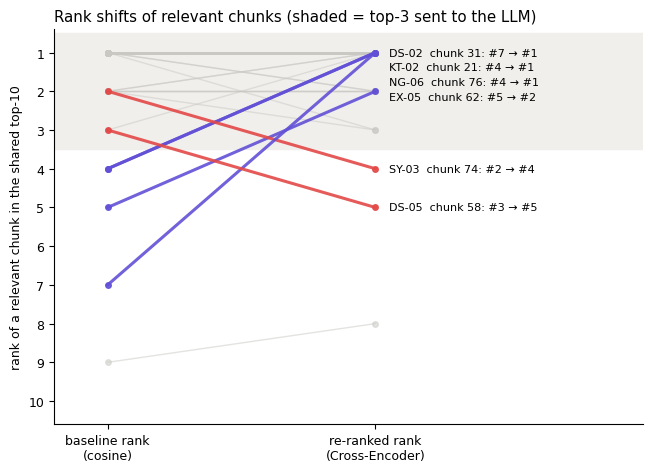

In [14]:
# colours: pipelines blue/orange; entered / left top-3 violet / red (colour-blind-safe pairs)
BASE, RR, UP, DOWN, GRAY, INK2 = "#2a78d6", "#eb6834", "#6250d6", "#e34948", "#c9c8c3", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

fig, ax = plt.subplots(figsize=(6.6, 4.8))
ax.axhspan(0.5, 3.5, color="#f0efec", zorder=0)
labels = []
for s in shifts.itertuples():
    col = UP if s.entered_top3 else DOWN if s.left_top3 else GRAY
    ax.plot([0, 1], [s.base_rank, s.rr_rank], color=col, lw=2.2 if col != GRAY else 1, alpha=0.9 if col != GRAY else 0.5,
            marker="o", ms=4, zorder=3 if col != GRAY else 2)
    if col != GRAY:
        labels.append((s.rr_rank, f"{s.query}  chunk {s.chunk}: #{s.base_rank} → #{s.rr_rank}"))
last = -9
for y, t in sorted(labels):
    y = max(y, last + 0.38); ax.text(1.05, y, t, va="center", fontsize=8); last = y
ax.set_ylim(10.6, 0.4); ax.set_xlim(-0.2, 2.0); ax.set_yticks(range(1, 11))
ax.set_xticks([0, 1], ["baseline rank\n(cosine)", "re-ranked rank\n(Cross-Encoder)"])
ax.set_ylabel("rank of a relevant chunk in the shared top-10")
ax.set_title("Rank shifts of relevant chunks (shaded = top-3 sent to the LLM)", loc="left")
plt.tight_layout(); plt.show()

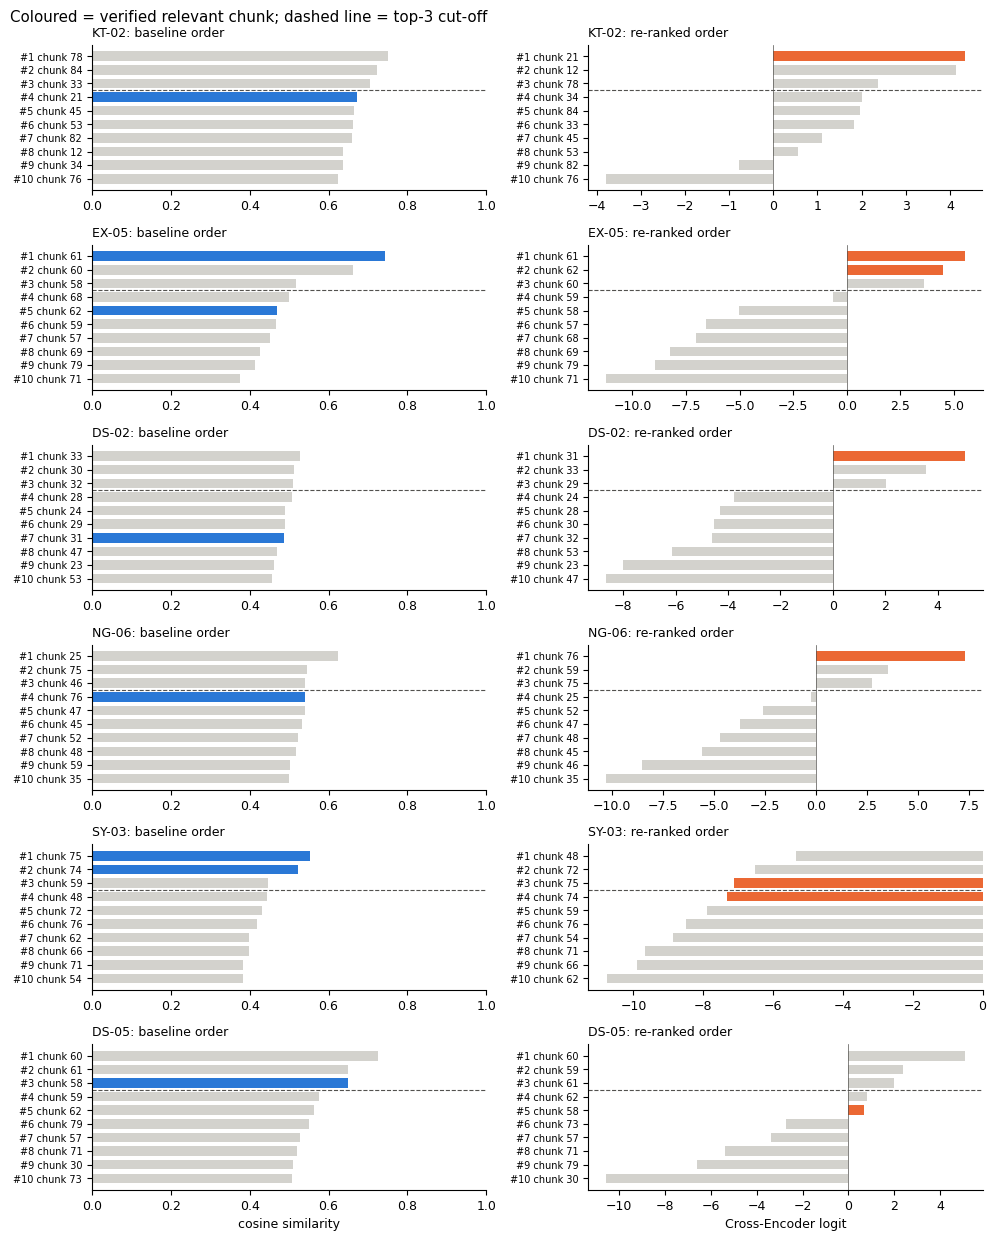

In [15]:
# the shared top-10 before and after re-ranking for the rescues and regressions;
# left = cosine similarity, right = Cross-Encoder logit (different scales, never compared directly)
CASES = ["KT-02", "EX-05", "DS-02", "NG-06", "SY-03", "DS-05"]
qrel = {q["query_id"]: set(q["relevant_chunk_ids"]) for q in questions}
fig, axes = plt.subplots(len(CASES), 2, figsize=(10, 2.1 * len(CASES)))
for i, qid in enumerate(CASES):
    c = pd.DataFrame(ev.set_index("query_id").loc[qid, "candidates"])
    c["relevant"] = c.chunk_id.isin(qrel[qid])
    for j, (order, score, col, xl) in enumerate((("baseline_rank", "cosine_score", BASE, "cosine similarity"),
                                                 ("reranked_rank", "ce_score", RR, "Cross-Encoder logit"))):
        ax, cc = axes[i, j], c.sort_values(order)
        ax.barh(range(10), cc[score], color=[col if r else "#d3d2cd" for r in cc.relevant], height=0.7)
        ax.set_yticks(range(10), [f"#{r} chunk {k}" for r, k in zip(cc[order], cc.chunk_id)], fontsize=7)
        ax.invert_yaxis(); ax.axhline(2.5, color=INK2, lw=0.8, ls="--"); ax.axvline(0, color=INK2, lw=0.5)
        ax.set_title(f"{qid}: {'baseline' if j == 0 else 're-ranked'} order", fontsize=9, loc="left")
        if j == 0: ax.set_xlim(0, 1)
        if i == len(CASES) - 1: ax.set_xlabel(xl)
fig.suptitle("Coloured = verified relevant chunk; dashed line = top-3 cut-off", x=0.01, ha="left")
plt.tight_layout(); plt.show()

**Answer 1 vs Answer 2 for the rescues and regressions.** Both answers were generated with the same prompt and settings on Vertex AI (the same backend as the latency benchmark) and reviewed manually against the verified reference answer. Each case was generated 5 times per pipeline; run 1 is shown here and the other runs are summarised in the next cell. The review is stored in `results/stress_test/stress_test_report.json`.

The saved answers are loaded by default; set `RERUN_STRESS_GENERATION = True` to regenerate them.

In [16]:
saved_gen = json.loads((RESULTS / "stress_test/generation_results.json").read_text())["cases"]
review = {c["query_id"]: c["manual_review"]
          for c in json.loads((RESULTS / "stress_test/stress_test_report.json").read_text())["generation_cases"]}
qtext = {q["query_id"]: q for q in questions}

for qid in CASES:
    r = ev.set_index("query_id").loc[qid]
    if RERUN_STRESS_GENERATION and client is not None:
        cands = baseline_retrieve(qtext[qid]["question"]); rr_ = rerank(qtext[qid]["question"], cands)
        a1, _ = generate(qtext[qid]["question"], cands[:3]); a2, _ = generate(qtext[qid]["question"], rr_[:3])
        note = "(regenerated now; the verdicts below refer to the saved answers)"
    else:
        a1, a2, note = saved_gen[qid]["answer_1"], saved_gen[qid]["answer_2"], "(saved answers)"
    rv = review[qid]
    display(Markdown(
        f"### {qid} ({qtext[qid]['category']}): {qtext[qid]['question']}\n\n"
        f"**Reference:** {qtext[qid]['reference_answer']}\n\n"
        f"**Rank shifts:** " + ", ".join(f"chunk {c} #{b}→#{x}" for c, b, x in r.shifts) +
        f" | top-3 {r.base_top3} → {r.rr_top3} | evidence coverage {r['base_evcov@3']:.2f} → {r['rr_evcov@3']:.2f} {note}\n\n"
        f"**Answer 1**, verdict *{rv['answer_1_verdict']}*:\n\n> " + (a1 or "-").replace("\n", "\n> ") +
        f"\n\n**Answer 2**, verdict *{rv['answer_2_verdict']}*:\n\n> " + (a2 or "-").replace("\n", "\n> ") +
        f"\n\n**Answer change: {rv['answer_change']}**. Missing in A1: {rv['missing_clauses']['answer_1'] or 'nothing'}; "
        f"missing in A2: {rv['missing_clauses']['answer_2'] or 'nothing'}"))

### KT-02 (keyword_trap): What CGPA does a student need in order to opt for the B.Tech (Honours) programme, and when can they opt?

**Reference:** A CGPA of 8.5 and above at the end of the third semester; the option is exercised during the fourth semester. The student must also have cleared all prescribed courses in the first attempt; students with a 'U' or 'W' grade in any course are not eligible.

**Rank shifts:** chunk 21 #4→#1 | top-3 [78, 84, 33] → [21, 12, 78] | evidence coverage 0.00 → 1.00 (saved answers)

**Answer 1**, verdict *insufficient_context*:

> To be awarded the B.Tech (Honours) degree, students must maintain an average CGPA of 8.5 [Chunk 84, p. 25]. If this CGPA is not maintained, they will be awarded only a B.Tech Degree [Chunk 84, p. 25].
> 
> The provided context does not specify when a student can opt for the B.Tech (Honours) programme, nor does it state a CGPA requirement for *opting* into the programme itself, only for the *award* of the degree.

**Answer 2**, verdict *correct*:

> A student needs a CGPA of 8.5 and above at the end of their third semester to opt for the B.Tech (Honours) programme [Chunk 21, p. 8]. They can opt for this programme during the fourth semester [Chunk 21, p. 8].
> 
> Additionally, to be eligible, students must have cleared all prescribed courses in the curriculum in the first attempt and must not have obtained a "U" or "W" grade in any course [Chunk 21, p. 8].

**Answer change: improved**. Missing in A1: ['CGPA 8.5 at end of 3rd semester', 'opt during 4th semester', 'cleared all courses in first attempt']; missing in A2: nothing

### EX-05 (exception): Can attendance below 85% be condoned for a student who was hospitalised?

**Reference:** Yes, for prolonged illness and/or hospitalisation with a medical certificate: the student must have more than 40% actual attendance, and the notional attendance (classes attended x 100 / (classes held in the semester minus classes held during the prolonged illness/hospitalisation)) must be at least 85%. Casual absenteeism and minor illnesses are not condoned.

**Rank shifts:** chunk 61 #1→#1, chunk 62 #5→#2 | top-3 [61, 60, 58] → [61, 62, 60] | evidence coverage 0.60 → 1.00 (saved answers)

**Answer 1**, verdict *partially_correct*:

> Yes, attendance below 85% can be condoned for a student who was hospitalized, provided they meet a specific condition. A student must have more than 40% attendance (calculated as per normal cases) to be eligible for condonation in cases of prolonged illness and/or hospitalization with a medical certificate [Chunk 61, p. 19].
> 
> This is in contrast to cases of minor illnesses and casual absenteeism, for which condonation of attendance is not permissible [Chunk 60, p. 19; Chunk 61, p. 19].

**Answer 2**, verdict *correct*:

> Yes, attendance below 85% can be condoned for a student who was hospitalized, provided they meet specific conditions.
> 
> For cases of prolonged illness and/or hospitalization with a medical certificate, a student must have more than 40% attendance, calculated based on the actual number of classes attended out of the total classes held till the date of compilation, to be eligible for condonation [Chunk 61, p. 19].
> 
> If eligible, a "Notional % of attendance" is calculated as:
> (Actual no. of classes attended x 100) / ((Total no. of classes held in the semester) - (No. of classes held during the days of prolonged illness and or hospitalization))
> This notional percentage must be ≥ 85% for condonation to be granted [Chunk 62, p. 19].
> 
> It is important to note that condonation is not permissible for cases of casual absenteeism or minor illnesses if attendance is below 85% [Chunk 60, p. 19; Chunk 61, p. 19].

**Answer change: improved**. Missing in A1: ['notional attendance must be >= 85% (formula excluding illness days)']; missing in A2: nothing

### DS-02 (document_specific): From the 2013 batch onwards, how many Humanities Pass/Fail (HPF) credits are required?

**Reference:** 4 non-CGPA credits under the Humanities Pass/Fail option (HPF) in the table for the 2013 batch onwards (the 2010 and 2011-2012 tables specify 2).

**Rank shifts:** chunk 31 #7→#1 | top-3 [33, 30, 32] → [31, 33, 29] | evidence coverage 0.00 → 1.00 (saved answers)

**Answer 1**, verdict *insufficient_context*:

> The provided context does not explicitly state the number of Humanities Pass/Fail (HPF) credits required for students from the 2013 batch onwards.
> 
> The context indicates that for the 2013 batch onwards, 7-13 credits of coursework done under the Pass/Fail option are not counted towards CGPA calculation [Chunk 33, p. 12]. Chunk 32, which applies to this batch, lists "Pass/ Fail Electives" (PPF) as 0-6 credits and "Industrial Lecture (Pass/Fail)" (PIL) as 1 credit under the Pass/Fail category [Chunk 32, p. 12]. However, "Humanities Pass/Fail" (HPF) is not mentioned.

**Answer 2**, verdict *correct*:

> For the 2013 batch onwards, 4 Humanities Pass/Fail (HPF) credits are required, which are non-CGPA credits [Chunk 31, p. 12].

**Answer change: improved**. Missing in A1: ['HPF = 4 credits']; missing in A2: nothing

### NG-06 (negation_constraint): Which courses is a student not allowed to repeat?

**Reference:** A course that has been successfully completed cannot be repeated. Exception: from academic year 2014-15, students who have taken all core and elective courses but still fail to reach the minimum CGPA of 5 (and so are not eligible for the degree) may repeat core or elective courses to earn the minimum CGPA.

**Rank shifts:** chunk 76 #4→#1 | top-3 [25, 75, 46] → [76, 59, 75] | evidence coverage 0.00 → 1.00 (saved answers)

**Answer 1**, verdict *insufficient_context*:

> The provided context does not state which courses a student is *not allowed* to repeat. It only specifies conditions under which courses *must* or *may* be repeated:
> *   A student who earns a U or W grade in a core course has to repeat it compulsorily when the course is offered next [Chunk 75, p. 22].
> *   A student securing a U or W grade in an elective course may repeat it if they desire to get a successful grade [Chunk 75, p. 22].
> 
> Therefore, based on the provided information, there are no courses explicitly stated as non-repeatable.

**Answer 2**, verdict *correct*:

> A student is generally not allowed to repeat a course that has been successfully completed [Chunk 76, p. 22].
> 
> However, for students from the academic year 2014-15 onwards, if they have completed all core and elective courses but fail to achieve a minimum CGPA of 5 and are thus ineligible for a degree, they are permitted to repeat core or elective courses to meet the minimum CGPA requirement [Chunk 76, p. 22].

**Answer change: improved**. Missing in A1: ['a successfully completed course cannot be repeated', '2014-15 exception for CGPA below 5']; missing in A2: nothing

### SY-03 (synonym_mismatch): How much time does a student have to dispute a grade they think is unfair?

**Reference:** The student can contact the teacher concerned within three weeks from the commencement of the semester immediately following the announcement of results; if the teacher finds the case genuine, he/she may re-examine and forward a revised grade to the Dean of Academic Courses through the Chairman of the Class Committee.

**Rank shifts:** chunk 74 #2→#4, chunk 75 #1→#3 | top-3 [75, 74, 59] → [48, 72, 75] | evidence coverage 1.00 → 0.50 (saved answers)

**Answer 1**, verdict *correct*:

> A student has three weeks from the commencement of the semester immediately following the announcement of the results to contact the teacher concerned if they feel aggrieved about a grade [Chunk 74, p. 22]. The student can access their answer paper(s) in the end semester examination, which may be shown to them by the teachers [Chunk 75, p. 22]. If the teacher finds the case genuine, they may re-examine it and forward a revised grade, if any, to the Dean of Academic Courses through the Chairman of the Class Committee with justification [Chunk 75, p. 22].

**Answer 2**, verdict *insufficient_context*:

> The provided context does not specify a time limit for a student to dispute a grade they think is unfair.
> 
> The ordinances state that a student shall have access to their end-semester examination answer paper(s) which may be shown by the teachers concerned. If the teacher deems the case genuine, they may re-examine it and forward a revised grade with justification [Chunk 75, p. 22]. However, no deadline for initiating this process is mentioned.

**Answer change: worsened**. Missing in A1: nothing; missing in A2: ['within three weeks from the commencement of the following semester']

### DS-05 (document_specific): What attendance code does a student with 90% attendance in a course receive?

**Reference:** 'G' (Good), which covers attendance of 85 to 94%.

**Rank shifts:** chunk 58 #3→#5 | top-3 [60, 61, 58] → [60, 59, 61] | evidence coverage 1.00 → 0.00 (saved answers)

**Answer 1**, verdict *correct*:

> A student with 90% attendance in a course receives an attendance code of "G" [Chunk 58, p. 18].

**Answer 2**, verdict *insufficient_context*:

> The provided context does not explicitly state what attendance code a student with 90% attendance in a course receives. The regulations only specify that if a student has less than 85% attendance, they should be assigned a "W" grade in that subject along with "P" as the attendance code [Chunk 60, p. 18]. For attendance not ≥ 85%, a "W" grade shall be awarded [Chunk 61, p. 19]. The context does not describe attendance codes for students meeting or exceeding the 85% minimum requirement.

**Answer change: worsened**. Missing in A1: nothing; missing in A2: ['85-94% -> G (Good)']

**Is the difference stable across runs?** Gemini's wording varies between identical calls, so each case was answered **5 times by both pipelines** (60 calls, Vertex AI, same retrieval, prompt and settings; `results/stress_test/generation_repeats.json`).

The cell below recomputes an automatic **key-fact check** on all 60 saved answers: does the answer state each fact of the reference answer? The patterns are stored with the runs. It is shown next to the manual verdicts, which were assigned after reading every answer.

In [17]:
reps = json.loads((RESULTS / "stress_test/generation_repeats.json").read_text())
key_facts = reps["metadata"]["key_facts"]
repeat_review = {r["query_id"]: r for r in
                 json.loads((RESULTS / "stress_test/stress_test_report.json").read_text())["repeat_runs"]["cases"]}
has_all = lambda qid, text: all(any(re.search(p, text, re.I) for p in pats) for pats in key_facts[qid].values())
rows = []
for qid in CASES:
    runs = [v for v in reps["runs"].values() if v["query_id"] == qid]
    assert all(r["baseline_top3"] == list(ev.set_index("query_id").loc[qid, "base_top3"]) for r in runs)
    rv = repeat_review[qid]
    rows.append({"case": qid, "runs": len(runs), "backend": runs[0]["llm_backend"].split(" (")[0],
                 "A1 all key facts": f"{sum(has_all(qid, r['answer_1']) for r in runs)}/{len(runs)}",
                 "A2 all key facts": f"{sum(has_all(qid, r['answer_2']) for r in runs)}/{len(runs)}",
                 "A1 verdicts (manual)": rv["answer_1_verdicts"], "A2 verdicts (manual)": rv["answer_2_verdicts"]})
display(pd.DataFrame(rows))
print("key facts checked:", {q: list(f) for q, f in key_facts.items()})

,case,runs,backend,A1 all key facts,A2 all key facts,A1 verdicts (manual),A2 verdicts (manual)
0,KT-02,5,Vertex AI,0/5,5/5,{'insufficient_context': 5},{'correct': 5}
1,EX-05,5,Vertex AI,0/5,5/5,{'partially_correct': 5},{'correct': 5}
2,DS-02,5,Vertex AI,0/5,5/5,{'insufficient_context': 5},{'correct': 5}
3,NG-06,5,Vertex AI,0/5,5/5,{'insufficient_context': 5},{'correct': 5}
4,SY-03,5,Vertex AI,5/5,0/5,{'correct': 5},{'insufficient_context': 5}
5,DS-05,5,Vertex AI,5/5,0/5,{'correct': 5},{'insufficient_context': 5}


key facts checked: {'KT-02': ['CGPA 8.5', 'measured at the end of the 3rd semester', 'opt during the 4th semester'], 'EX-05': ['actual attendance above 40%', 'notional attendance must reach 85%'], 'DS-02': ['HPF = 4 credits'], 'NG-06': ['successfully completed courses cannot be repeated', '2014-15 exception (CGPA below 5)'], 'SY-03': ['within three weeks'], 'DS-05': ['attendance code G']}


## 8. Latency profiling and scaling

**Method:**

- Every step is timed with `time.perf_counter()`.
- Models are warmed up first; loading and indexing are excluded.
- Each pass runs one shared retrieval: Pipeline 1 takes its top-3, Pipeline 2 adds Cross-Encoder scoring and sorting.

**What runs here:**

- the retrieval-side timing, live, for all 33 questions (5 repeats if `RERUN_FULL_LATENCY`, otherwise 1);
- the Gemini timings: 15 paired runs on Vertex AI, loaded from `results/latency/raw_generation_timings.csv`, with statistics recomputed here.

In [18]:
def timed_query(query):
    t0 = time.perf_counter(); q = embed([query])
    t1 = time.perf_counter(); scores, rows = index.search(q, TOP_K_RETRIEVE)
    t2 = time.perf_counter(); cands = [chunks_by_id[id_map[int(r)]] for r in rows[0]]
    t3 = time.perf_counter(); p1 = cands[:3]                                       # Pipeline 1 selection
    t4 = time.perf_counter(); ce = cross_encoder.predict([(query, c["text"]) for c in cands], show_progress_bar=False)
    t5 = time.perf_counter(); p2 = [cands[i] for i in np.argsort(-ce, kind="stable")[:3]]   # sort + top-3
    t6 = time.perf_counter()
    ms = lambda a, b: (b - a) * 1000
    return {"query_embed_ms": ms(t0, t1), "faiss_search_ms": ms(t1, t2), "ce_score_ms": ms(t4, t5),
            "sort_select_ms": ms(t5, t6), "p1_retrieval_ms": ms(t0, t4), "p2_retrieval_ms": ms(t0, t3) + ms(t4, t6)}

for _ in range(3):
    timed_query("warm-up query")                       # exclude one-off initialisation
reps = 5 if RERUN_FULL_LATENCY else 1
lat = pd.DataFrame([timed_query(q["question"]) for _ in range(reps) for q in questions])
stats = lambda df: df.agg(["count", "mean", "median", "std"]).T.round(3)
print(f"live retrieval-side timing: {len(questions)} questions x {reps} repeat(s) (ms)")
display(stats(lat))
print(f"additional re-ranking time (CE + sort): {(lat.ce_score_ms + lat.sort_select_ms).mean():.1f} ms (mean) | "
      f"slowdown P2/P1: {lat.p2_retrieval_ms.mean() / lat.p1_retrieval_ms.mean():.1f}x (mean)")

saved_ret = pd.read_csv(RESULTS / "latency/raw_retrieval_timings.csv")
print(f"\nsaved full benchmark ({len(saved_ret)} runs = {saved_ret.query_id.nunique()} questions x 5 repeats):")
display(stats(saved_ret[lat.columns]))

live retrieval-side timing: 33 questions x 1 repeat(s) (ms)


,count,mean,median,std
query_embed_ms,33.0,8.364,8.720,1.456
faiss_search_ms,33.0,0.061,0.069,0.014
ce_score_ms,33.0,216.550,198.246,40.148
sort_select_ms,33.0,0.026,0.027,0.003
p1_retrieval_ms,33.0,8.436,8.801,1.471
p2_retrieval_ms,33.0,225.012,207.834,40.817


additional re-ranking time (CE + sort): 216.6 ms (mean) | slowdown P2/P1: 26.7x (mean)

saved full benchmark (165 runs = 33 questions x 5 repeats):


,count,mean,median,std
query_embed_ms,165.0,10.217,9.959,1.880
faiss_search_ms,165.0,0.068,0.069,0.020
ce_score_ms,165.0,265.037,253.340,50.413
sort_select_ms,165.0,0.018,0.017,0.006
p1_retrieval_ms,165.0,10.298,10.039,1.886
p2_retrieval_ms,165.0,275.352,263.994,50.690


15 completed paired runs | backend: Vertex AI (project=lma-ass1, location=global) | identical settings: True
API attempts: 37 (31 ok, 6 failed; failures excluded)


,count,mean,median,std
gen1_ms,15.0,4465.213,4473.5,2217.392
gen2_ms,15.0,5745.780,3256.3,6600.380
p1_end_to_end_ms,15.0,4495.860,4510.4,2214.414
p2_end_to_end_ms,15.0,6034.640,3504.7,6591.336


end-to-end P2/P1: 0.78x (median), 1.34x (mean)
tokens: 21505 input, 15663 output+thinking -> ~$0.046 at assumed list prices ($0.30 / $2.50 per 1M)


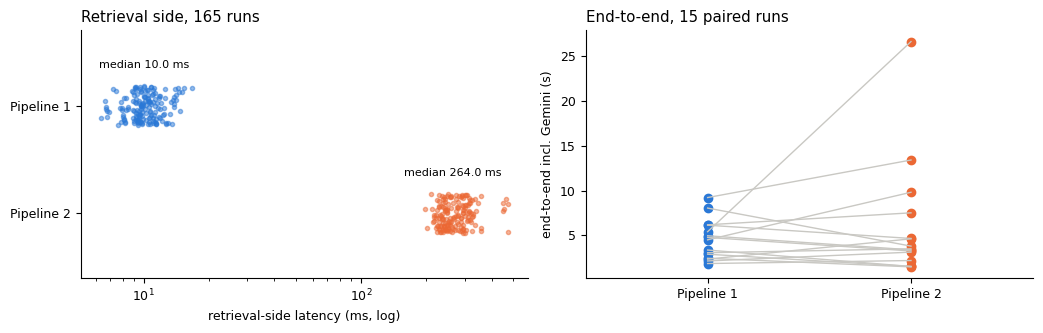

In [19]:
gen = pd.read_csv(RESULTS / "latency/raw_generation_timings.csv")         # completed pairs (Vertex AI)
att = pd.read_csv(RESULTS / "latency/raw_generation_attempts.csv")        # every API attempt incl. failures
print(f"{len(gen)} completed paired runs | backend: {gen.backend.unique()[0]} | identical settings: {gen.settings.nunique() == 1}")
print(f"API attempts: {len(att)} ({(att.status == 'ok').sum()} ok, {(att.status != 'ok').sum()} failed; failures excluded)")
display(stats(gen[["gen1_ms", "gen2_ms", "p1_end_to_end_ms", "p2_end_to_end_ms"]]))
print(f"end-to-end P2/P1: {gen.p2_end_to_end_ms.median() / gen.p1_end_to_end_ms.median():.2f}x (median), "
      f"{gen.p2_end_to_end_ms.mean() / gen.p1_end_to_end_ms.mean():.2f}x (mean)")
tok_in = gen[["gen1_input_tokens", "gen2_input_tokens"]].values.sum()
tok_out = gen[["gen1_output_tokens", "gen2_output_tokens", "gen1_thinking_tokens", "gen2_thinking_tokens"]].values.sum()
print(f"tokens: {tok_in} input, {tok_out} output+thinking -> ~${tok_in / 1e6 * 0.30 + tok_out / 1e6 * 2.50:.3f} "
      f"at assumed list prices ($0.30 / $2.50 per 1M)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.4))
for k, (col, c) in enumerate((("p1_retrieval_ms", BASE), ("p2_retrieval_ms", RR))):
    v = saved_ret[col]; a1.scatter(v, k + np.random.default_rng(0).uniform(-.18, .18, len(v)), s=9, color=c, alpha=.5)
    a1.text(v.median(), k - .35, f"median {v.median():.1f} ms", ha="center", fontsize=8)
a1.set_xscale("log"); a1.set_yticks([0, 1], ["Pipeline 1", "Pipeline 2"]); a1.set_ylim(1.6, -.7)
a1.set_xlabel("retrieval-side latency (ms, log)"); a1.set_title(f"Retrieval side, {len(saved_ret)} runs", loc="left")
for r in gen.itertuples():
    a2.plot([0, 1], [r.p1_end_to_end_ms / 1000, r.p2_end_to_end_ms / 1000], color=GRAY, lw=1)
a2.scatter([0] * len(gen), gen.p1_end_to_end_ms / 1000, color=BASE); a2.scatter([1] * len(gen), gen.p2_end_to_end_ms / 1000, color=RR)
a2.set_xticks([0, 1], ["Pipeline 1", "Pipeline 2"]); a2.set_xlim(-.6, 1.6)
a2.set_ylabel("end-to-end incl. Gemini (s)"); a2.set_title(f"End-to-end, {len(gen)} paired runs", loc="left")
plt.tight_layout(); plt.show()

Cross-Encoder ms by #pairs (median): {1: 19.8, 10: 190.5, 20: 475.2, 40: 974.8, 85: 2223.2} | ~26.5 ms/pair
extrapolated CE over every chunk, per query (NOT measured): {1000: '27 s', 10000: '265 s', 100000: '2,652 s'}
FAISS top-10 search ms by index size (median): {85: 0.005, 10000: 0.485, 100000: 16.997}
saved full scaling run (5 queries x 5): CE ms {'1': 31, '5': 102, '10': 232, '20': 545, '40': 1197, '85': 2677} | FAISS ms {'85': 0.037, '1000 (synthetic)': 0.053, '10000 (synthetic)': 0.571, '100000 (synthetic)': 9.802, '500000 (synthetic)': 51.865}


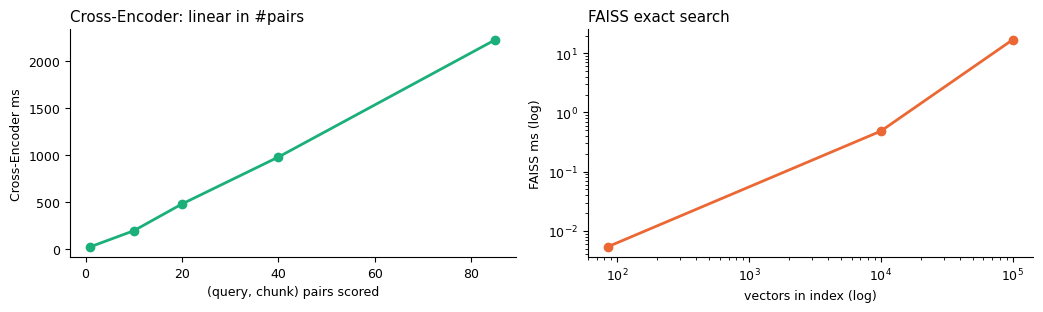

In [20]:
# Scaling: Cross-Encoder cost vs number of pairs (85 = the whole corpus), measured live on 2 queries x 3 repeats;
# FAISS exact search vs index size (sizes > 85 use synthetic random unit vectors: cost depends only on N and d).
ce_rows = []
for q in [questions[0]["question"], questions[16]["question"]]:
    order = baseline_retrieve(q, k=len(chunks))
    for n in (1, 10, 20, 40, len(chunks)):
        for _ in range(3):
            t0 = time.perf_counter()
            cross_encoder.predict([(q, c["text"]) for c in order[:n]], show_progress_bar=False)
            ce_rows.append({"pairs": n, "ms": (time.perf_counter() - t0) * 1000})
ce_df = pd.DataFrame(ce_rows).groupby("pairs").ms.median()
per_pair = np.polyfit(ce_df.index, ce_df.values, 1)[0]

rng, qv, fz = np.random.default_rng(SEED), embed([questions[0]["question"]]), {}
for n in (len(chunks), 10_000, 100_000):
    if n == len(chunks):
        idx = index
    else:
        x = rng.standard_normal((n, index.d), dtype=np.float32); x /= np.linalg.norm(x, axis=1, keepdims=True)
        idx = faiss.IndexFlatIP(index.d); idx.add(x)
    idx.search(qv, 10); ts = []
    for _ in range(5):
        t0 = time.perf_counter(); idx.search(qv, 10); ts.append((time.perf_counter() - t0) * 1000)
    fz[n] = float(np.median(ts))

print("Cross-Encoder ms by #pairs (median):", ce_df.round(1).to_dict(), f"| ~{per_pair:.1f} ms/pair")
print("extrapolated CE over every chunk, per query (NOT measured):",
      {n: f"{per_pair * n / 1000:,.0f} s" for n in (1_000, 10_000, 100_000)})
print("FAISS top-10 search ms by index size (median):", {n: round(v, 3) for n, v in fz.items()})
saved_sc = json.loads((RESULTS / "latency/latency_summary.json").read_text())["scaling"]
print("saved full scaling run (5 queries x 5): CE ms", {k: round(v["median"]) for k, v in saved_sc["cross_encoder_vs_pairs_ms"].items()},
      "| FAISS ms", {k: round(v["median"], 3) for k, v in saved_sc["faiss_vs_index_size_ms"].items()})

fig, (b1, b2) = plt.subplots(1, 2, figsize=(10.5, 3.2))
b1.plot(ce_df.index, ce_df.values, marker="o", color="#1baf7a", lw=2)
b1.set_xlabel("(query, chunk) pairs scored"); b1.set_ylabel("Cross-Encoder ms"); b1.set_title("Cross-Encoder: linear in #pairs", loc="left")
b2.plot(list(fz), list(fz.values()), marker="o", color=RR, lw=2); b2.set_xscale("log"); b2.set_yscale("log")
b2.set_xlabel("vectors in index (log)"); b2.set_ylabel("FAISS ms (log)"); b2.set_title("FAISS exact search", loc="left")
plt.tight_layout(); plt.show()

## 9. Result figures

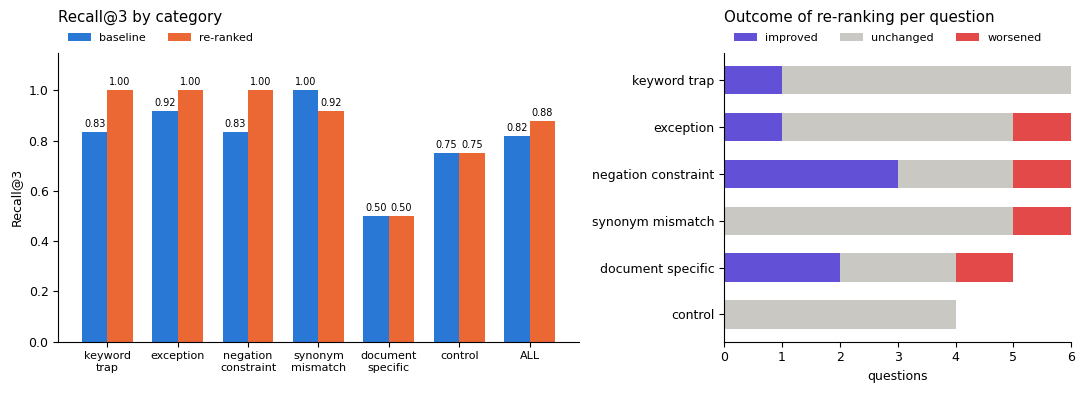

In [21]:
fig, (c1, c2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.5, 1]})
x = np.arange(len(CATS) + 1)
vals_b = list(by_cat["base_recall@3"]) + [ev["base_recall@3"].mean()]
vals_r = list(by_cat["rr_recall@3"]) + [ev["rr_recall@3"].mean()]
c1.bar(x - .18, vals_b, .36, color=BASE, label="baseline"); c1.bar(x + .18, vals_r, .36, color=RR, label="re-ranked")
for xi, vb, vr in zip(x, vals_b, vals_r):
    c1.text(xi - .18, vb + .02, f"{vb:.2f}", ha="center", fontsize=7); c1.text(xi + .18, vr + .02, f"{vr:.2f}", ha="center", fontsize=7)
c1.set_xticks(x, [c.replace("_", "\n") for c in CATS] + ["ALL"], fontsize=8); c1.set_ylim(0, 1.15)
c1.set_ylabel("Recall@3"); c1.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
c1.set_title("Recall@3 by category", loc="left", pad=22)

oc = ev.groupby(["category", "outcome"]).size().unstack(fill_value=0).reindex(CATS)[["improved", "unchanged", "worsened"]]
left = np.zeros(len(oc))
for col, c in (("improved", UP), ("unchanged", GRAY), ("worsened", DOWN)):
    c2.barh(range(len(oc)), oc[col], left=left, color=c, label=col, height=.6); left += oc[col].values
c2.set_yticks(range(len(oc)), [c.replace("_", " ") for c in CATS]); c2.invert_yaxis()
c2.legend(frameon=False, ncol=3, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0)); c2.set_xlabel("questions")
c2.set_title("Outcome of re-ranking per question", loc="left", pad=22)
plt.tight_layout(); plt.show()

### Summary of the measured results

- **Retrieval, 33 questions:** Recall@3 0.818 → 0.879 and MRR@10 0.801 → 0.863.
  - 4 verified rescues: KT-02 keyword trap (chunk 21 #4→#1), EX-05 exception (chunk 62 #5→#2), DS-02 near-identical tables (chunk 31 #7→#1) and NG-06 negation (chunk 76 #4→#1). Each turned a refusal or an incomplete Answer 1 into a correct Answer 2.
  - 2 regressions: SY-03 and DS-05, where the key chunk dropped out of the top-3 and Answer 2 lost the information.
  - 1 question (C-04) had no relevant chunk in the top-10, so re-ranking could not help.
- **Latency:** re-ranking adds ≈ 265 ms per query, making retrieval ≈ 27× slower. End-to-end, Gemini (≈ 3.3–4.5 s median, up to 26 s) dominates; its run-to-run variance is far larger than the re-ranking step, so the end-to-end ratios (0.78× median, 1.34× mean) do not resolve the re-ranking cost.
- **Scaling:** Cross-Encoder cost grows linearly with the number of chunks scored (≈ 2.7 s per query for this 85-chunk corpus). Bi-Encoder search over 100k vectors takes only milliseconds. That is why the Cross-Encoder re-ranks a small candidate set instead of the whole collection.

The numbers above come from the saved runs. The live cells in this notebook reproduce the retrieval results exactly; timings vary slightly from run to run.